# Taller 3 - Solucion completa de la Unidad 3

Electiva IV: Gestion de Datos con Python.

Este cuaderno resuelve los ejercicios pendientes de los tres cuadernillos y los
requerimientos adicionales del taller general. Los originales se conservan.
Las temperaturas son **datos sinteticos**, no mediciones reales de Tunja.
Los empleados proceden del CSV original enlazado por el docente.

**Enfoque funcional:** se usan funciones, `map`, `filter`, `starmap` y operaciones
vectorizadas de NumPy y Pandas. No se usan sentencias `if`/`else`, expresiones
condicionales, ciclos `for`/`while` ni comprensiones. Las transformaciones devuelven
resultados nuevos; los ejemplos que requieren modificar una copia, las graficas y
la escritura de archivos conservan los efectos externos necesarios del ejercicio.

## Preparacion
Ejecute las celdas en orden. Se requiere Python con NumPy, Pandas, Matplotlib,
PyTables (`tables`), OpenPyXL, lxml y ReportLab. En un entorno nuevo de Jupyter
puede instalarlos con `%pip install numpy pandas matplotlib tables openpyxl lxml reportlab`.
La celda siguiente tambien reconoce las dependencias locales usadas para verificar este taller.
Los archivos exportados se guardan en `salidas_taller3`.

In [1]:
from pathlib import Path
from itertools import product, starmap
import sys

BASE = next(filter(lambda ruta: (ruta / 'datos' / 'employees.csv').exists(),
                   (Path.cwd(), Path.cwd() / 'taller 3')), Path.cwd())
dependencias = BASE.parent / '.taller3_deps'
sys.path[:0] = list(map(str, filter(Path.is_dir, (dependencias,))))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SALIDAS = BASE / 'salidas_taller3'
SALIDAS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})
print('NumPy:', np.__version__, 'Pandas:', pd.__version__)

NumPy: 2.5.4 Pandas: 3.0.1


## 1. NumPy
### 1.1 Temperaturas sinteticas y muestreo cada media hora

`linspace(4, 19, 48)` fija la **cantidad** de valores, incluye ambos extremos y
calcula el paso: `(19 - 4) / 47`. `arange(4, 19, paso)` fija el **paso** y excluye
el extremo superior. Usamos `15 / 48` para obtener 48 temperaturas comparables.
`uniform(4, 19, 48)` genera valores aleatorios sin una separacion fija entre temperaturas.

Para un dia hay 48 muestras: 00:00, 00:30, ..., 23:30. El eje se muestra hasta
24:00; incluir una muestra en 24:00 daria 49 puntos y corresponderia al inicio
del dia siguiente. El paso de tiempo de 0.5 horas es distinto del paso entre temperaturas.
`permutation` desordena los valores sin modificar el arreglo original.

,Hora,Linspace,Arange,Uniforme
0,0.0,7.510638,8.6875,15.609341
1,0.5,4.638298,18.6875,10.583177
2,1.0,8.787234,6.1875,16.878969
3,1.5,9.425532,14.6250,14.460520
4,2.0,9.106383,17.1250,5.412660


,Linspace,Arange,Uniforme
count,48.0,48.0000,48.000000
min,4.0,4.0000,4.657056
max,19.0,18.6875,18.634335


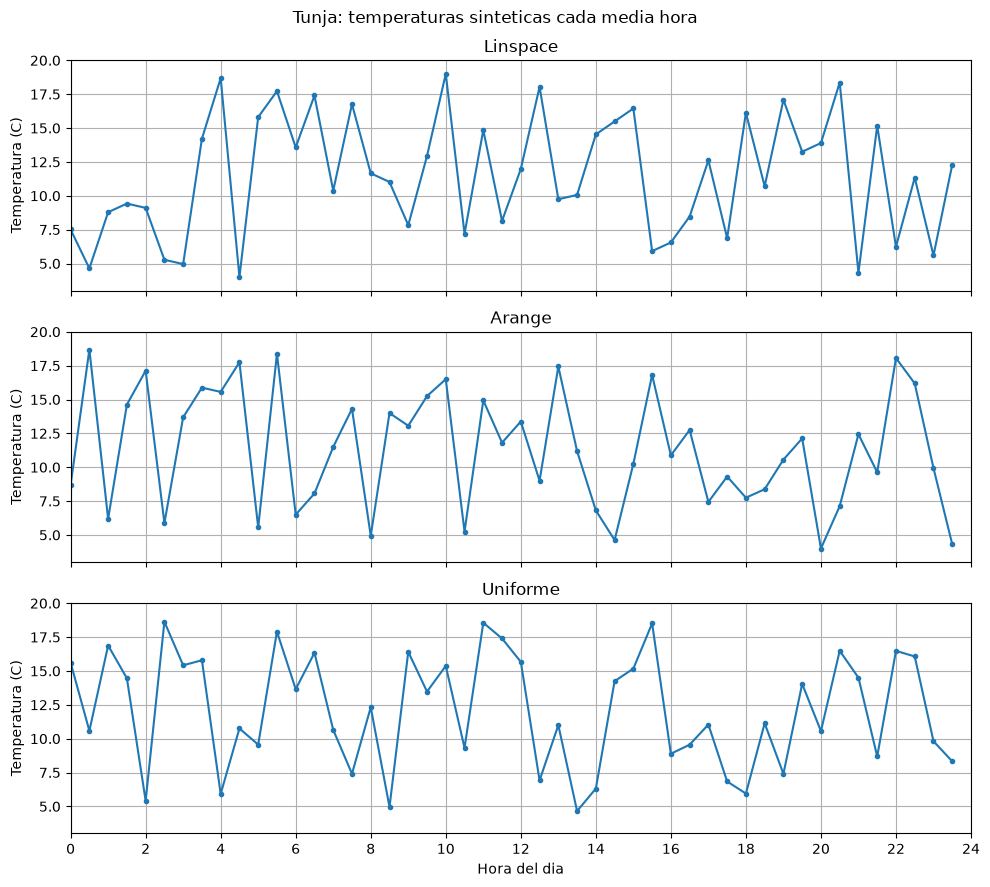

In [2]:
rng = np.random.default_rng(42)
horas = np.arange(0, 24, 0.5)
temperaturas_linspace = np.linspace(4, 19, len(horas))
temperaturas_arange = np.arange(4, 19, 15 / len(horas))
temperaturas_uniformes = rng.uniform(4, 19, len(horas))

temperaturas = pd.DataFrame({
    'Hora': horas,
    'Linspace': rng.permutation(temperaturas_linspace),
    'Arange': rng.permutation(temperaturas_arange),
    'Uniforme': temperaturas_uniformes,
})
display(temperaturas.head())
display(temperaturas.drop(columns='Hora').agg(['count', 'min', 'max']))
fig, ejes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)

def graficar_temperatura(eje, columna, datos):
    eje.plot(datos['Hora'], datos[columna], marker='o', markersize=3)
    eje.set(title=columna, ylabel='Temperatura (C)', xlim=(0, 24), ylim=(3, 20))
    eje.set_xticks(np.arange(0, 25, 2))
    return eje

ejes_configurados = tuple(map(
    lambda par: graficar_temperatura(par[0], par[1], temperaturas),
    zip(ejes, ['Linspace', 'Arange', 'Uniforme']),
))
ejes[-1].set_xlabel('Hora del dia')
fig.suptitle('Tunja: temperaturas sinteticas cada media hora')
fig.tight_layout()
plt.show()

**Comparacion:** la uniforme evita la separacion artificial constante entre valores,
pero una serie independiente y desordenada puede saltar muchos grados en media hora.
Ninguno de estos tres procedimientos representa por si solo la evolucion diaria real.
Un ciclo suave con ruido pequeno es una alternativa temporalmente mas plausible.
La siguiente curva es ilustrativa, sin calibracion meteorologica: minimo aproximado
a las 03:00 y maximo a las 15:00. `clip` garantiza el rango solicitado [4, 19].

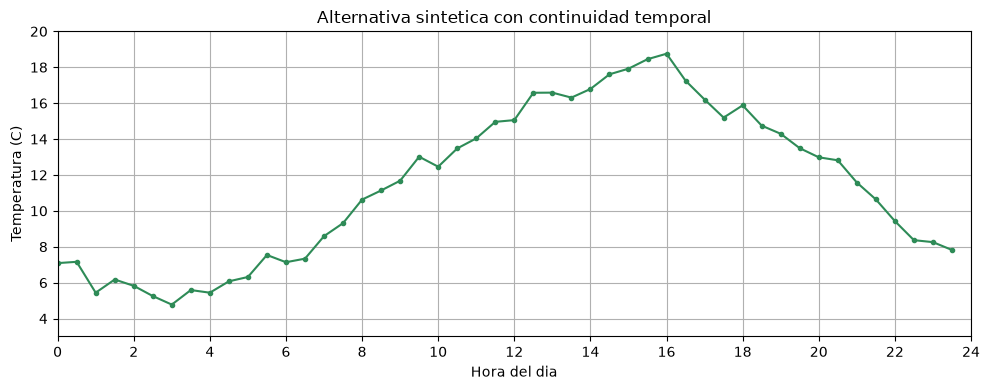

In [3]:
ciclo = 11.5 + 6 * np.cos(2 * np.pi * (horas - 15) / 24)
temperatura_ciclica = np.clip(ciclo + rng.normal(0, 0.5, len(horas)), 4, 19)
plt.plot(horas, temperatura_ciclica, marker='.', color='seagreen')
plt.title('Alternativa sintetica con continuidad temporal')
plt.xlabel('Hora del dia')
plt.ylabel('Temperatura (C)')
plt.xlim(0, 24)
plt.xticks(np.arange(0, 25, 2))
plt.ylim(3, 20)
plt.tight_layout()
plt.show()

### 1.2 Ejercicio 1 del cuadernillo: desordenar ytemperatures
Se conservan los 20 valores entre 13.6 y 18.2, pero cambia su orden.
El eje de este ejemplo es el numero de muestra, como en el cuadernillo.

[14.32631579 15.53684211 16.50526316 16.74736842 16.98947368 17.47368421
 16.02105263 17.23157895 13.84210526 15.05263158 13.6        15.29473684
 14.56842105 17.95789474 14.81052632 18.2        17.71578947 14.08421053
 15.77894737 16.26315789]


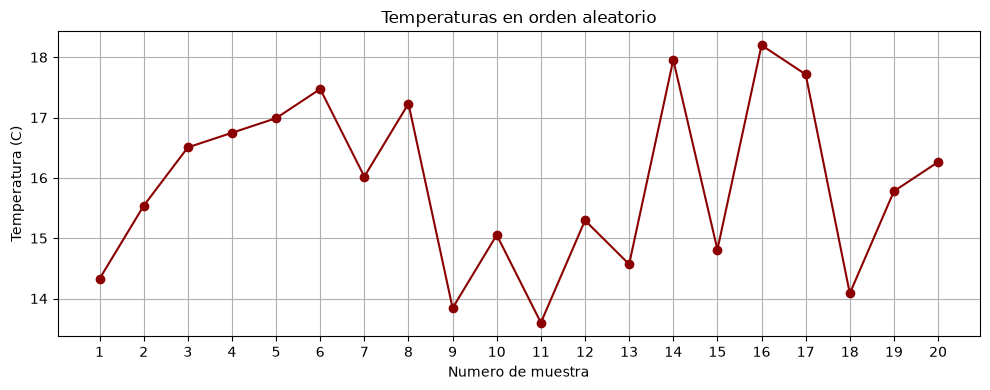

In [4]:
ytemperatures = np.linspace(13.6, 18.2, 20)
y_desordenadas = np.random.default_rng(7).permutation(ytemperatures)
print(y_desordenadas)
plt.plot(np.arange(1, 21), y_desordenadas, marker='o', color='darkred')
plt.xlabel('Numero de muestra')
plt.ylabel('Temperatura (C)')
plt.title('Temperaturas en orden aleatorio')
plt.xticks(np.arange(1, 21))
plt.tight_layout()
plt.show()

### 1.3 Ejercicio 2: funciones de NumPy

El enunciado escribe `bitcount()`. Se interpreta como **`bincount()`**, por su
combinacion con `argmax()` para encontrar la moda. No existe `np.bitcount`.
`np.bitwise_count`, disponible desde NumPy 2, cuenta bits encendidos y tiene otro proposito.
Fuente: [documentacion de bincount](https://numpy.org/doc/stable/reference/generated/numpy.bincount.html).

`bincount` cuenta cada entero no negativo; la posicion indica el valor y el contenido
indica su frecuencia. `argmax` devuelve la primera posicion con frecuencia maxima.
En un empate devuelve el menor valor empatado en este caso.

In [5]:
valores = np.array([0, 1, 1, 2, 2, 2, 4])
frecuencias = np.bincount(valores)
print('Frecuencias:', frecuencias)
print('Moda:', frecuencias.argmax())

Frecuencias: [1 2 3 0 1]
Moda: 2


`hstack`, `vstack` y `dstack` apilan arreglos. Con dos vectores, producen
respectivamente un vector concatenado, una matriz de filas y un arreglo de tres
dimensiones con los pares en el ultimo eje. `tolist()` convierte a listas de Python.

In [6]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
apilados = dict(map(lambda funcion: (funcion.__name__, funcion((a, b))),
                    (np.hstack, np.vstack, np.dstack)))
print('hstack:', apilados['hstack'], 'Forma:', apilados['hstack'].shape)
print('vstack:', apilados['vstack'], 'Forma:', apilados['vstack'].shape)
print('dstack:', apilados['dstack'], 'Forma:', apilados['dstack'].shape)
print('Lista:', a.tolist(), type(a.tolist()))

hstack: [1 2 3 4 5 6] Forma: (6,)
vstack: [[1 2 3]
 [4 5 6]] Forma: (2, 3)
dstack: [[[1 4]
  [2 5]
  [3 6]]] Forma: (1, 3, 2)
Lista: [1, 2, 3] <class 'list'>


`pad` agrega bordes. `comparison.all()` significa aplicar `all()` a un arreglo
booleano llamado `comparison`: devuelve verdadero si **todos** sus elementos lo son.
`flipud` invierte el eje de las filas y `flip` permite elegir el eje.
`isin` comprueba pertenencia elemento a elemento.

In [7]:
matriz = np.array([[1, 2], [3, 4]])
print('pad:\n', np.pad(matriz, 1, mode='constant', constant_values=0))
comparison = matriz == np.array([[1, 2], [3, 9]])
print('Comparacion:\n', comparison)
print('Todos iguales:', comparison.all())
print('flipud:\n', np.flipud(matriz))
print('flip en columnas:\n', np.flip(matriz, axis=1))
print('isin:\n', np.isin(matriz, [2, 4]))

pad:
 [[0 0 0 0]
 [0 1 2 0]
 [0 3 4 0]
 [0 0 0 0]]
Comparacion:
 [[ True  True]
 [ True False]]
Todos iguales: False
flipud:
 [[3 4]
 [1 2]]
flip en columnas:
 [[2 1]
 [4 3]]
isin:
 [[False  True]
 [False  True]]


`flatten` aplana y crea una copia. `unique` obtiene valores distintos (ordenados por
defecto) y puede contar sus frecuencias. `asarray` convierte una entrada en arreglo,
sin copiar si recibe un arreglo compatible. `where` selecciona valores segun una condicion.

In [8]:
plano = matriz.flatten()
plano[0] = 99
print('Copia aplanada:', plano, '\nOriginal:\n', matriz)
unicos, conteos = np.unique([3, 1, 3, 2, 1], return_counts=True)
print('Unicos:', unicos, 'Frecuencias:', conteos)
arreglo = np.asarray([10, 20, 30])
print('asarray:', arreglo, 'Reutiliza arreglo:', np.asarray(arreglo) is arreglo)
print('where:', np.where(arreglo >= 20, 'alto', 'bajo'))

Copia aplanada: [99  2  3  4] 
Original:
 [[1 2]
 [3 4]]
Unicos: [1 2 3] Frecuencias: [2 1 2]
asarray: [10 20 30] Reutiliza arreglo: True
where: ['bajo' 'alto' 'alto']


### 1.4 Ejercicio 3: matriz 6 x 6 con borde de unos
Se parte de 4 x 4 ceros y se agrega un borde de ancho 1. No se necesitan ciclos.

In [9]:
borde = np.pad(np.zeros((4, 4), dtype=int), 1, constant_values=1)
print(borde)

[[1 1 1 1 1 1]
 [1 0 0 0 0 1]
 [1 0 0 0 0 1]
 [1 0 0 0 0 1]
 [1 0 0 0 0 1]
 [1 1 1 1 1 1]]


### 1.5 Ejercicio 4: invertir un vector
El cuadernillo solicita hacerlo sin funciones especificas y el taller general pide
variantes con NumPy. Se muestran ambas: slicing `[::-1]` y `np.flip`.
El paso -1 del slicing recorre los elementos de derecha a izquierda.

In [10]:
vector = np.array([1, 2, 3, 4, 5, 6])
print('Slicing:', vector[::-1])
print('NumPy flip:', np.flip(vector))
print('NumPy take:', np.take(vector, np.arange(vector.size - 1, -1, -1)))

Slicing: [6 5 4 3 2 1]
NumPy flip: [6 5 4 3 2 1]
NumPy take: [6 5 4 3 2 1]


### 1.6 Ejercicio 5: ravel y sus ordenes
`C` recorre primero el ultimo indice (filas en 2D); `F`, el primero (columnas).
`A` usa F si el arreglo es contiguo en orden Fortran y C en otro caso.
`K` sigue la disposicion en memoria, respetando la inversion de ejes con pasos negativos.
`ravel` devuelve un arreglo 1D y solo copia cuando lo necesita; `flatten` siempre copia.
Fuente: [documentacion de ravel](https://numpy.org/doc/stable/reference/generated/numpy.ravel.html).

In [11]:
matriz_c = np.array([[1, 2, 3], [4, 5, 6]])
matriz_f = np.asfortranarray(matriz_c)
variantes = product([('C-contiguo', matriz_c), ('F-contiguo', matriz_f)], ['C', 'F', 'A', 'K'])
resultados_ravel = pd.DataFrame(list(starmap(
    lambda caso, orden: {'Arreglo': caso[0], 'Orden': orden,
                         'Resultado': np.ravel(caso[1], order=orden).tolist()},
    variantes,
)))
display(resultados_ravel)
# Este arreglo no es contiguo ni en C ni en F: A y K pueden diferir.
vista = np.arange(12).reshape(2, 3, 2).swapaxes(1, 2)
print('Vista no contigua, A:', vista.ravel(order='A'))
print('Vista no contigua, K:', vista.ravel(order='K'))

Vista no contigua, A: [ 0  2  4  1  3  5  6  8 10  7  9 11]
Vista no contigua, K: [ 0  1  2  3  4  5  6  7  8  9 10 11]


,Arreglo,Orden,Resultado
0,C-contiguo,C,"[1, 2, 3, 4, 5, 6]"
1,C-contiguo,F,"[1, 4, 2, 5, 3, 6]"
2,C-contiguo,A,"[1, 2, 3, 4, 5, 6]"
3,C-contiguo,K,"[1, 2, 3, 4, 5, 6]"
4,F-contiguo,C,"[1, 2, 3, 4, 5, 6]"
5,F-contiguo,F,"[1, 4, 2, 5, 3, 6]"
6,F-contiguo,A,"[1, 4, 2, 5, 3, 6]"
7,F-contiguo,K,"[1, 4, 2, 5, 3, 6]"


### 1.7 Ejercicios 6 y 7: distribuciones normal y uniforme
La normal concentra mas observaciones cerca de su media; la uniforme asigna
igual densidad a todo su intervalo. Un histograma aproxima la distribucion.
Las alturas no seran exactas debido al azar. La semilla permite repetir el experimento.

Normal: media -0.002072643966707596 desviacion 1.0056212265519275
Uniforme: media 0.4974315666095974 desviacion 0.2872656055015396


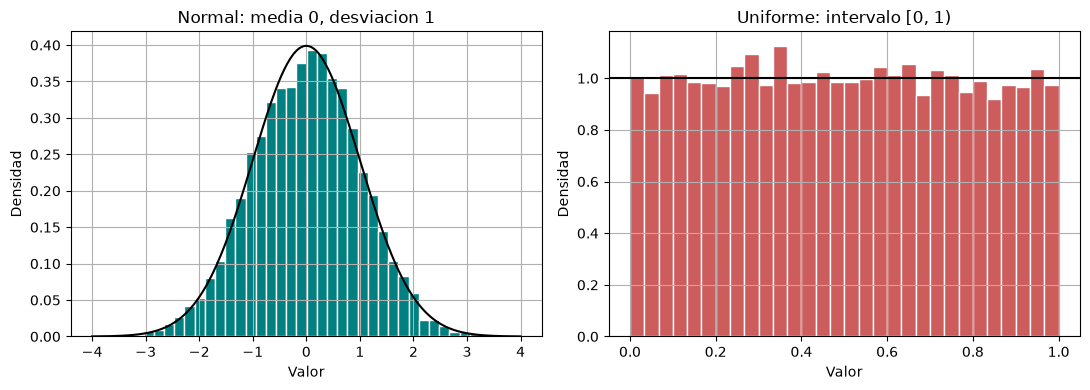

In [12]:
rng_distribuciones = np.random.default_rng(2026)
normal = rng_distribuciones.normal(loc=0, scale=1, size=10000)
uniforme = rng_distribuciones.uniform(low=0, high=1, size=10000)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].hist(normal, bins=40, density=True, color='teal', edgecolor='white')
x = np.linspace(-4, 4, 300)
ejes[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color='black')
ejes[0].set(title='Normal: media 0, desviacion 1', xlabel='Valor', ylabel='Densidad')
ejes[1].hist(uniforme, bins=30, density=True, color='indianred', edgecolor='white')
ejes[1].axhline(1, color='black')
ejes[1].set(title='Uniforme: intervalo [0, 1)', xlabel='Valor', ylabel='Densidad')
fig.tight_layout()
plt.show()
print('Normal: media', normal.mean(), 'desviacion', normal.std())
print('Uniforme: media', uniforme.mean(), 'desviacion', uniforme.std())

## 2. Pandas: Series y DataFrames
### 2.1 Insertar series: insert y assign
`insert` modifica el DataFrame y ubica la columna en una posicion concreta.
`assign` devuelve un nuevo DataFrame. Al asignar una Serie, Pandas alinea por etiquetas
del indice, no solamente por la posicion de los valores.

In [13]:
personas = pd.DataFrame({'Nombre': ['Ana', 'Luis', 'Marta']}, index=[10, 20, 30])
edades = pd.Series([22, 25, 28], index=[10, 20, 30])
def insertar_serie(datos, posicion, nombre, serie):
    copia = datos.copy()
    copia.insert(posicion, nombre, serie)
    return copia

personas_con_edad = insertar_serie(personas, 1, 'Edad', edades)
con_mayoria = personas_con_edad.assign(Mayor_de_edad=lambda df: df['Edad'] >= 18)
display(personas_con_edad)
display(con_mayoria)

,Nombre,Edad
10,Ana,22
20,Luis,25
30,Marta,28


,Nombre,Edad,Mayor_de_edad
10,Ana,22,True
20,Luis,25,True
30,Marta,28,True


### 2.2 Merge left y right
`left` conserva todas las claves de la tabla izquierda y `right`, las de la derecha.
Si no hay coincidencia, las columnas del otro lado quedan nulas. Si hay claves
duplicadas, un merge puede multiplicar las filas; aqui verificamos una relacion uno a uno.

In [14]:
izquierda = pd.DataFrame({'Nombre': ['Carmen', 'Luis', 'Maria'],
                          'Sexo': ['Mujer', 'Hombre', 'Mujer']})
derecha = pd.DataFrame({'Nombre': ['Maria', 'Pedro', 'Luis'], 'Edad': [25, 30, 18]})
print('LEFT')
display(izquierda.merge(derecha, on='Nombre', how='left', validate='one_to_one'))
print('RIGHT')
display(izquierda.merge(derecha, on='Nombre', how='right', validate='one_to_one'))

LEFT
RIGHT


,Nombre,Sexo,Edad
0,Carmen,Mujer,NaN
1,Luis,Hombre,18.0
2,Maria,Mujer,25.0


,Nombre,Sexo,Edad
0,Maria,Mujer,25
1,Pedro,NaN,30
2,Luis,Hombre,18


### 2.3 Pivot y melt
`pivot` transforma una tabla larga en ancha; requiere una unica observacion por
combinacion de indice y columna. Si hay duplicados y se quiere agregarlos se usa
`pivot_table`. `melt` transforma columnas de medidas en filas, conservando identificadores.

In [15]:
ventas = pd.DataFrame({'Persona': ['Ana', 'Ana', 'Luis', 'Luis'],
                      'Mes': ['Enero', 'Febrero', 'Enero', 'Febrero'],
                      'Venta': [100, 120, 90, 150]})
ancha = ventas.pivot(index='Persona', columns='Mes', values='Venta')
larga = ancha.reset_index().melt(id_vars='Persona', var_name='Mes', value_name='Venta')
display(ventas)
display(ancha)
display(larga)

,Persona,Mes,Venta
0,Ana,Enero,100
1,Ana,Febrero,120
2,Luis,Enero,90
3,Luis,Febrero,150


Mes,Enero,Febrero
Persona,,
Ana,100,120
Luis,90,150


,Persona,Mes,Venta
0,Ana,Enero,100
1,Luis,Enero,90
2,Ana,Febrero,120
3,Luis,Febrero,150


### 2.4 Cargar los empleados originales
Se usa el [CSV enlazado por el docente](https://drive.google.com/uc?export=download&id=1TJrHAQo-wrZe0zmbXGYehhDf1-58-kmK).
Hay una copia en `datos/employees.csv`. Si falta, se intenta leer la fuente publica.
Este es el archivo con `First Name`, `Salary` y `Team`, no el archivo Oracle HR de
otro ejemplo del cuadernillo. Nunca se reemplazan estos datos por empleados inventados.

In [16]:
URL_EMPLEADOS = 'https://drive.google.com/uc?export=download&id=1TJrHAQo-wrZe0zmbXGYehhDf1-58-kmK'
ARCHIVO_EMPLEADOS = BASE / 'datos' / 'employees.csv'

def cargar_empleados():
    fuente = next(filter(Path.exists, (ARCHIVO_EMPLEADOS,)), URL_EMPLEADOS)
    df = pd.read_csv(fuente)
    requeridas = {'First Name', 'Gender', 'Salary', 'Team'}
    assert requeridas.issubset(df.columns), 'La fuente no contiene las columnas de empleados.'
    return df

df_emp = cargar_empleados()
print('Filas y columnas:', df_emp.shape)
display(df_emp.head())

Filas y columnas: (1000, 8)


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### Actividad 1. Identificar nulos
`info()` muestra tipos y cantidad de valores no nulos. `isna().sum()` cuenta los
nulos por columna, para saber exactamente donde falta informacion.

In [17]:
df_emp.info()
display(df_emp.isna().sum().rename('Valores nulos'))

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 62.6+ KB


First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
Name: Valores nulos, dtype: int64

### Actividad 2. Reemplazar nulos por 0
Se crea una copia. Convertir a `object` permite insertar el numero 0 incluso en
columnas de texto con tipos estrictos de Pandas. Es la operacion pedida, aunque
un cero no tiene un significado natural para un nombre o un equipo desconocido.

In [18]:
df_sin_nulos = df_emp.astype(object).fillna(0)
display(df_sin_nulos.head(10))
print('Nulos restantes:', df_sin_nulos.isna().sum().sum())

Nulos restantes: 0


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.17,True,0
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.34,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services
5,Dennis,Male,4/18/1987,1:35 AM,115163,10.125,False,Legal
6,Ruby,Female,8/17/1987,4:20 PM,65476,10.012,True,Product
7,0,Female,7/20/2015,10:43 AM,45906,11.598,0,Finance
8,Angela,Female,11/22/2005,6:29 AM,95570,18.523,True,Engineering
9,Frances,Female,8/8/2002,6:51 AM,139852,7.524,True,Business Development


### Actividades 3 y 4. Recargar y eliminar filas incompletas
Se vuelve a leer el CSV antes de `dropna`, porque rellenar con ceros ocultaria los nulos.
Sin `subset`, `dropna()` elimina cualquier fila con al menos un dato faltante.

In [19]:
df_emp = cargar_empleados()
df_completos = df_emp.dropna()
print('Filas originales:', len(df_emp))
print('Filas completas:', len(df_completos))
print('Filas eliminadas:', len(df_emp) - len(df_completos))
display(df_completos.head())

Filas originales: 1000
Filas completas: 764
Filas eliminadas: 236


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services
5,Dennis,Male,4/18/1987,1:35 AM,115163,10.125,False,Legal


### Actividad 5. Tipos de datos
Los nombres, el genero y el equipo son texto. Las fechas y horas llegan como
cadenas porque `read_csv` no las convierte automaticamente en fechas. En versiones
anteriores de Pandas muchas de estas columnas aparecen como `object`; en Pandas 3
pueden inferirse como `str`. `object` tambien permite objetos de distintos tipos,
como booleanos con nulos. Por eso debe observarse la salida, no asumir que todas
las columnas seran `object`. Los salarios y bonos se reconocen como numeros.

In [20]:
display(df_emp.dtypes.rename('Tipo'))
fechas = pd.to_datetime(df_emp['Start Date'], format='%m/%d/%Y')
print('Fecha convertida:', fechas.dtype)

Fecha convertida: datetime64[us]


First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary                 int64
Bonus %              float64
Senior Management     object
Team                     str
Name: Tipo, dtype: object

### Actividad 6. Empleados del equipo Finance
Se trabaja sobre los originales, para no excluir empleados de Finance que tengan
un nombre u otro campo nulo. La mascara selecciona solamente ese equipo.

In [21]:
finanzas = df_emp.loc[df_emp['Team'].eq('Finance')]
print('Empleados en Finance:', len(finanzas))
display(finanzas)

Empleados en Finance: 102


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
7,NaN,Female,7/20/2015,10:43 AM,45906,11.598,NaN,Finance
14,Kimberly,Female,1/14/1999,7:13 AM,41426,14.543,True,Finance
46,Bruce,Male,11/28/2009,10:47 PM,114796,6.796,False,Finance
...,...,...,...,...,...,...,...,...
907,Elizabeth,Female,7/27/1998,11:12 AM,137144,10.081,False,Finance
954,Joe,Male,1/19/1980,4:06 PM,119667,1.148,True,Finance
987,Gloria,Female,12/8/2014,5:08 AM,136709,10.331,True,Finance
992,Anthony,Male,10/16/2011,8:35 AM,112769,11.625,True,Finance


### Actividad 7. Seleccionar tres columnas y el indice 100
`loc[100]` selecciona la etiqueta 100; con el indice original equivale a la fila
numero 101. `iloc[100]` seleccionaria la posicion 100 independientemente de su etiqueta.

In [22]:
df_emp = cargar_empleados()
df_tres_columnas = df_emp[['First Name', 'Gender', 'Salary']].copy()
display(df_tres_columnas.loc[[100]])

,First Name,Gender,Salary
100,Melissa,Female,48109


### Actividad 8. Ordenar salarios
Los dos DataFrames contienen todos los empleados. Se muestran las primeras diez
filas de cada uno para comparar los extremos sin imprimir dos mil filas.

In [23]:
salario_ascendente = df_emp.sort_values('Salary', ascending=True)
salario_descendente = df_emp.sort_values('Salary', ascending=False)
display(salario_ascendente.head(10))
display(salario_descendente.head(10))

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
576,Michael,Male,7/30/1993,5:35 PM,35013,14.879,False,Product
238,Kevin,Male,3/25/1982,7:31 AM,35061,5.128,False,Legal
82,Steven,Male,3/30/1980,9:20 PM,35095,8.379,True,Client Services
63,Matthew,Male,1/2/2013,10:33 PM,35203,18.040,False,Human Resources
650,Cynthia,Female,7/5/1986,1:24 AM,35381,11.749,False,Finance
900,Christina,Female,6/23/2002,3:18 PM,35477,18.178,False,Human Resources
530,Kathleen,Female,6/13/2014,9:16 AM,35575,14.595,False,Distribution
762,Terry,Male,11/10/2004,4:33 AM,35633,3.947,True,Distribution
964,Bruce,Male,5/7/1980,8:00 PM,35802,12.391,True,Sales
906,Frances,Female,5/16/2014,8:31 AM,35884,17.667,False,Sales


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
644,Katherine,Female,8/13/1996,12:21 AM,149908,18.912,False,Finance
429,Rose,Female,5/28/2015,8:40 AM,149903,5.630,False,Human Resources
828,Cynthia,Female,7/12/2006,8:55 AM,149684,7.864,False,Product
186,NaN,Female,2/23/2005,9:50 PM,149654,1.825,NaN,Sales
160,Kathy,Female,3/18/2000,7:26 PM,149563,16.991,True,Finance
740,Russell,NaN,5/9/2009,11:59 AM,149456,3.533,False,Marketing
793,Andrea,Female,7/22/1999,9:25 AM,149105,13.707,True,Distribution
981,James,Male,1/15/1993,5:19 PM,148985,19.280,False,Legal
800,Clarence,Male,8/5/1989,6:11 PM,148941,11.517,False,Product
844,Maria,NaN,6/19/1985,1:48 AM,148857,8.738,False,Legal


### Actividad 9. Salario mayor que 49000 y menor que 50000
Los limites son estrictos: 49000 y 50000 no se incluyen. `&` combina condiciones
elemento a elemento; cada condicion se encierra entre parentesis.

In [24]:
filtro_salario = df_emp.loc[
    (df_emp['Salary'] > 49000) & (df_emp['Salary'] < 50000),
    ['First Name', 'Salary'],
]
display(filtro_salario)

,First Name,Salary
52,Todd,49339
125,Patricia,49368
229,Jeremy,49542
414,Gary,49101
583,Diane,49501
664,Timothy,49473
752,Henry,49665
834,Carl,49325
920,Rose,49538


### Actividad 10. Renombrar First Name como Nombre
`rename` cambia el encabezado, sin alterar los valores de la columna.

In [25]:
df_renombrado = df_emp.rename(columns={'First Name': 'Nombre'})
display(df_renombrado.head())

,Nombre,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### Actividades 11, 12 y 13. Conteo, maximo y promedio
`len` cuenta filas, incluso cuando el nombre es nulo. `count()` sobre el nombre
contaria solo nombres no nulos. `max` y `mean` se aplican al salario original.

In [26]:
cantidad_item_9 = len(filtro_salario)
mayor_salario = df_emp['Salary'].max()
promedio_salarios = df_emp['Salary'].mean()
print('11. Filas del punto 9:', cantidad_item_9)
print('12. Mayor salario:', mayor_salario)
print('13. Promedio de salarios:', promedio_salarios)

11. Filas del punto 9: 9
12. Mayor salario: 149908
13. Promedio de salarios: 90662.181


## 3. Pandas: archivos y nube
### 3.1 Compartir un archivo de Google Drive
1. Subir el archivo a Drive y abrir **Compartir**.
2. En **Acceso general**, elegir **Cualquier persona con el enlace**.
3. Elegir el rol **Lector** si solo se requiere consultar o descargar.
4. Copiar el enlace, guardar los cambios y probarlo sin iniciar sesion.

Una cuenta institucional puede restringir esa opcion. Un enlace de vista previa
puede devolver HTML y no el CSV: para `read_csv` se necesita la descarga del archivo.
No se ha cambiado ningun permiso de su cuenta; estos son los pasos solicitados.
Fuente: [Ayuda oficial de Google Drive](https://support.google.com/drive/answer/2494822?hl=es).

### 3.2 HDF5: crear, cargar, consultar y agregar
HDF5 es un formato binario organizado en grupos y conjuntos de datos. Permite
almacenar varios conjuntos en un archivo y comprimirlos. Pandas utiliza PyTables.
El formato `table` admite consultas y anexar filas; `fixed` se orienta a guardar
y recuperar el objeto completo. Solo se deben cargar archivos HDF de confianza.

**Ejercicio:** guardar tres mediciones, agregar una cuarta, consultar temperaturas
mayores que 12 y almacenar tambien un resumen bajo otra clave.
Fuente: [entrada y salida con Pandas](https://pandas.pydata.org/docs/user_guide/io.html#hdf5-pytables).

In [27]:
mediciones = pd.DataFrame({'hora': [0.0, 0.5, 1.0], 'temperatura': [8.0, 12.5, 13.0]})
ruta_hdf = SALIDAS / 'mediciones.h5'
with pd.HDFStore(ruta_hdf, mode='w') as almacen:
    almacen.put('mediciones', mediciones, format='table', data_columns=['temperatura'])
    nueva = pd.DataFrame({'hora': [1.5], 'temperatura': [14.0]}, index=[3])
    almacen.append('mediciones', nueva, format='table')
    promedio = almacen.select('mediciones')['temperatura'].mean()
    almacen.put('resumen', pd.DataFrame({'promedio': [promedio]}))
    print('Claves:', almacen.keys())
    display(almacen.select('mediciones', where='temperatura > 12'))
recuperadas = pd.read_hdf(ruta_hdf, key='mediciones')
display(recuperadas)

Claves: ['/mediciones', '/resumen']


,hora,temperatura
1,0.5,12.5
2,1.0,13.0
3,1.5,14.0


,hora,temperatura
0,0.0,8.0
1,0.5,12.5
2,1.0,13.0
3,1.5,14.0


### 3.3 HTML: crear y recuperar una tabla
HTML describe la estructura de una pagina. `to_html` crea una tabla y `read_html`
devuelve una **lista** de DataFrames, uno por tabla encontrada. El formato no conserva
necesariamente los tipos originales. Se usa un resumen numerico para comprobar la lectura.

**Ejercicio:** calcular cantidad de empleados y salario promedio por equipo,
publicar el resumen como archivo HTML local y recuperarlo.
Fuente: [HTML en Pandas](https://pandas.pydata.org/docs/user_guide/io.html#html).

In [28]:
resumen_equipos = (
    df_emp.assign(Team=df_emp['Team'].fillna('Sin equipo'))
    .groupby('Team', as_index=False)
    .agg(Empleados=('Salary', 'size'), Salario_promedio=('Salary', 'mean'))
    .assign(Salario_promedio=lambda df: df['Salario_promedio'].round(2))
)
ruta_html = SALIDAS / 'resumen_equipos.html'
pagina = ('<!doctype html><html lang="es"><head><meta charset="utf-8">'
          '<title>Resumen por equipo</title></head><body>'
          '<h1>Resumen de empleados por equipo</h1>'
          + resumen_equipos.to_html(index=False, border=1)
          + '</body></html>')
ruta_html.write_text(pagina, encoding='utf-8')
tablas = pd.read_html(ruta_html, encoding='utf-8')
display(tablas[0])
print('Tablas recuperadas:', len(tablas))

Tablas recuperadas: 1


,Team,Empleados,Salario_promedio
0,Business Development,101,91866.32
1,Client Services,106,88224.42
2,Distribution,90,88500.47
3,Engineering,92,94269.20
4,Finance,102,92219.48
5,Human Resources,91,90944.53
6,Legal,88,89303.61
7,Marketing,98,90435.59
8,Product,95,88665.51
9,Sales,94,92173.44


### 3.4 PDF desde un DataFrame
Pandas no incluye `to_pdf`. Se convierten las columnas y filas en una tabla de
ReportLab. `SimpleDocTemplate` organiza el documento y `repeatRows=1` repite la
cabecera si la tabla ocupa varias paginas. PDF conserva la presentacion, pero no
es el formato indicado para continuar un analisis de datos.

**Ejercicio:** exportar el resumen por equipo con titulo, unidades y fuente.

In [29]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle

ruta_pdf = SALIDAS / 'resumen_equipos.pdf'
estilos = getSampleStyleSheet()
formatear_fila = lambda fila: [fila.Team, str(fila.Empleados), f'{fila.Salario_promedio:,.2f}']
filas_pdf = [['Equipo', 'Empleados', 'Salario promedio']] + list(map(
    formatear_fila, resumen_equipos.itertuples(index=False),
))
tabla_pdf = Table(filas_pdf, colWidths=[190, 100, 160], repeatRows=1)
tabla_pdf.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#176B62')),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
    ('ALIGN', (1, 1), (-1, -1), 'RIGHT'),
    ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#F0F4F3')]),
    ('BOTTOMPADDING', (0, 0), (-1, -1), 9),
    ('TOPPADDING', (0, 0), (-1, -1), 9),
    ('LINEBELOW', (0, 0), (-1, 0), 1, colors.HexColor('#176B62')),
]))
documento = SimpleDocTemplate(str(ruta_pdf), pagesize=A4)
documento.build([
    Paragraph('Empleados por equipo', estilos['Title']),
    Paragraph('Cantidad de registros y promedio de Salary. La fuente no especifica moneda.', estilos['BodyText']),
    Spacer(1, 16), tabla_pdf, Spacer(1, 16),
    Paragraph('Fuente: employees.csv enlazado en el cuadernillo de la Unidad 3. '
              'Sin equipo agrupa los registros cuyo Team esta vacio.', estilos['BodyText']),
])
print('PDF generado:', ruta_pdf.name)

PDF generado: resumen_equipos.pdf


### 3.5 Excel: una hoja por equipo
`ExcelWriter` mantiene abierto un libro mientras `to_excel` escribe cada grupo.
`groupby('Team')` separa empleados por equipo. Los 43 registros sin equipo se guardan
en una hoja adicional llamada `Sin equipo`, para no perder informacion.
Los nombres del dataset son validos para hojas de Excel y no necesitan modificacion.
`index=False` evita exportar una columna extra con el indice de Pandas.
Fuente: [Excel en Pandas](https://pandas.pydata.org/docs/user_guide/io.html#excel-files).

In [30]:
from openpyxl.styles import Font, PatternFill
from openpyxl.utils import get_column_letter

ruta_excel = SALIDAS / 'empleados_por_equipo.xlsx'
equipos_exportar = df_emp['Team'].fillna('Sin equipo')

def formatear_cabecera(celda):
    celda.font = Font(bold=True, color='FFFFFF')
    celda.fill = PatternFill('solid', fgColor='176B62')
    return celda.coordinate

def ajustar_columna(hoja, grupo, numero, columna):
    ancho = max(len(columna), int(grupo[columna].astype(str).fillna('').str.len().max())) + 3
    hoja.column_dimensions[get_column_letter(numero)].width = ancho
    return ancho

def formatear_numeros(fila):
    fila[0].number_format = '#,##0'
    fila[1].number_format = '0.000'
    return fila[0].row

def exportar_equipo(escritor, equipo, grupo):
    grupo.to_excel(escritor, sheet_name=equipo, index=False)
    hoja = escritor.sheets[equipo]
    hoja.freeze_panes = 'A2'
    hoja.auto_filter.ref = hoja.dimensions
    tuple(map(formatear_cabecera, hoja[1]))
    tuple(starmap(lambda numero, columna: ajustar_columna(hoja, grupo, numero, columna),
                  enumerate(grupo.columns, start=1)))
    tuple(map(formatear_numeros, hoja.iter_rows(min_row=2, min_col=5, max_col=6)))
    return equipo, len(grupo)

with pd.ExcelWriter(ruta_excel, engine='openpyxl') as escritor:
    equipos_exportados = dict(starmap(
        lambda equipo, grupo: exportar_equipo(escritor, equipo, grupo),
        df_emp.groupby(equipos_exportar, sort=True),
    ))

hojas_recuperadas = pd.read_excel(ruta_excel, sheet_name=None)
conteos = dict(starmap(lambda nombre, df: (nombre, len(df)), hojas_recuperadas.items()))
display(pd.Series(conteos, name='Filas'))
print('Total exportado:', sum(map(len, hojas_recuperadas.values())))

Total exportado: 1000


Business Development    101
Client Services         106
Distribution             90
Engineering              92
Finance                 102
Human Resources          91
Legal                    88
Marketing                98
Product                  95
Sales                    94
Sin equipo               43
Name: Filas, dtype: int64

## 4. Verificaciones
Estas comprobaciones contrastan limites, conteos y lecturas de los archivos exportados.
Un `assert` sin mensaje de error significa que se cumple la condicion evaluada.

In [31]:
assert len(horas) == 48 and horas[0] == 0 and horas[-1] == 23.5
assert np.allclose(np.diff(horas), 0.5)
assert temperaturas.drop(columns='Hora').ge(4).all().all()
assert temperaturas.drop(columns='Hora').le(19).all().all()
assert np.array_equal(np.sort(y_desordenadas), ytemperatures)
assert borde.shape == (6, 6) and borde.sum() == 20
assert np.all(borde[1:-1, 1:-1] == 0)
assert np.array_equal(vector[::-1], np.flip(vector))
assert len(df_emp) == len(df_completos) + len(df_emp[df_emp.isna().any(axis=1)])
assert df_sin_nulos.isna().sum().sum() == 0
assert filtro_salario['Salary'].between(49000, 50000, inclusive='neither').all()
assert len(recuperadas) == 4 and np.isclose(recuperadas['temperatura'].mean(), 11.875)
pd.testing.assert_frame_equal(tablas[0], resumen_equipos, check_dtype=False)
assert set(hojas_recuperadas) == set(equipos_exportar.unique())
def verificar_equipo(equipo, recuperado):
    esperado = df_emp.loc[equipos_exportar.eq(equipo)].reset_index(drop=True)
    pd.testing.assert_frame_equal(recuperado, esperado, check_dtype=False)
    return True

assert all(starmap(verificar_equipo, hojas_recuperadas.items()))
assert sum(map(len, hojas_recuperadas.values())) == len(df_emp)
print('Todas las verificaciones finalizaron correctamente.')

Todas las verificaciones finalizaron correctamente.


## 5. Ideas para sustentar

- **Programacion funcional:** `map` transforma cada elemento, `filter` selecciona
  mediante un predicado y `starmap` entrega cada tupla como argumentos separados.
  `product` genera combinaciones para comparar los ordenes de `ravel`.
  Las condiciones se expresan como mascaras o predicados, sin sentencias condicionales.
  `map` es perezoso: `list`, `tuple` o `dict` consumen sus resultados. En las exportaciones
  ese consumo garantiza que se escriban todas las hojas antes de cerrar el archivo.
- **NumPy:** trabajo con arreglos, operaciones vectorizadas y semillas reproducibles.
  Distingo cantidad de puntos (`linspace`) de paso (`arange`) y muestreo temporal.
- **Pandas:** una Serie representa una columna; un DataFrame organiza varias columnas.
  Las mascaras filtran filas y `loc` selecciona etiquetas y columnas.
- **Nulos:** rellenar y eliminar son decisiones diferentes. Recargo el original para
  que un ejercicio no cambie accidentalmente los resultados del siguiente.
- **Archivos:** HDF5 conserva datos estructurados, HTML presenta tablas, PDF presenta
  un informe y Excel permite distribuir los empleados en hojas por equipo.
- **Validacion:** compruebo que los archivos se pueden volver a leer y que Excel
  conserva todos los registros, incluidos los empleados sin equipo.

Para practicar: explique por que hay 48 muestras y no 24; por que se usa `&` en el
filtro salarial; por que `len` y `count` pueden diferir; y por que `dropna` no debe
ejecutarse despues de reemplazar los nulos si se quiere detectar las filas incompletas.